<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/PCVK_Ganjil_2026-2027_FadhilTaufiqurrachman/blob/main/Week3PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 3 - Operasi Dasar Citra Digital

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pengolahan Citra Dan Visi Komputer

In [1]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Fadhil Taufiqurrachman'
NIM  = '244107020090'

N    = int(NIM[-3:])

PARAM = {
    'b'    : (N % 61) + 20,
    'a'    : round(1.0 + (N % 9) / 10, 1),
    'c'    : (N % 20) + 30,
    'gamma': round(0.4 + (N % 6) * 0.25, 2),
    'bit'  : (N % 6) + 2,
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s : %s' % (k, v))

print('WAKTU  :', waktu.strftime("%Y-%m-%d %H:%M:%S %Z"))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Fadhil Taufiqurrachman
NIM    : 244107020090 | N = 90
b      : 49
a      : 1.0
c      : 40
gamma  : 0.4
bit    : 2
WAKTU  : 2026-09-18 21:19:34 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 0eded3538759a315


In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /PCVK Image/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Praktikum Operasi Citra Sederhana**

--- Mengubah tingkat kecerahan citra ---
Masukkan nilai kecerahan: 49


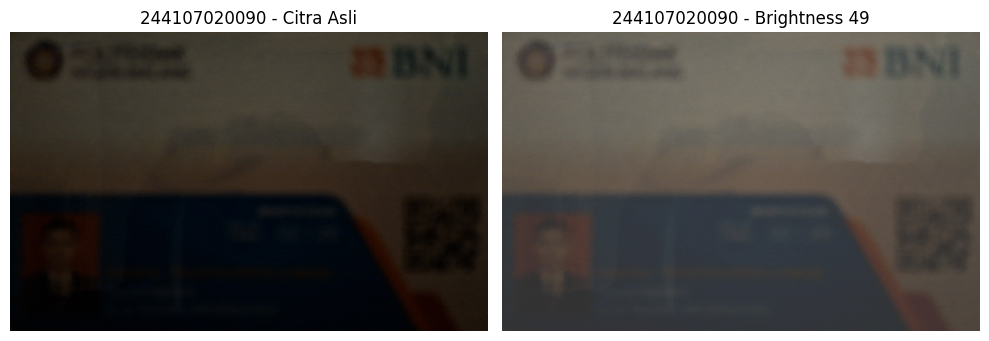

In [3]:
# Import library
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# =========================================================================
# Percobaan Transformasi Linier Brightness
# =========================================================================
print('--- Mengubah tingkat kecerahan citra ---')
try:
    brightness = int(input('Masukkan nilai kecerahan: '))
except ValueError:
    print('Error, not a number')
    brightness = 0

image_path = BASE_PATH + 'KTM1a.jpg'

# Baca citra
original = cv.imread(image_path)

if original is None:
    print(f"Error: Gambar tidak ditemukan di {image_path}. Pastikan file sudah diunggah.")
else:
    # Ubah format warna dari BGR (bawaan OpenCV) ke RGB (untuk Matplotlib)
    original_rgb = cv.cvtColor(original, cv.COLOR_BGR2RGB)

    # Buat kanvas kosong dengan ukuran dan tipe data yang sama
    brightness_image = np.zeros(original_rgb.shape, original_rgb.dtype)

    # Melakukan perulangan akses per piksel
    for y in range(original_rgb.shape[0]):
        for x in range(original_rgb.shape[1]):
            for c in range(original_rgb.shape[2]):
                # Operasi penambahan brightness dengan fungsi clip/truncate
                brightness_image[y,x,c] = np.clip(original_rgb[y,x,c] + brightness, 0, 255)

    # Menampilkan hasil
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(original_rgb)
    axes[0].set_title(NIM + ' - Citra Asli')
    axes[0].axis('off')

    axes[1].imshow(brightness_image)
    axes[1].set_title(NIM + ' - Brightness ' + str(brightness))
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

**Tugas Praktikum**

1. Inverse Citra

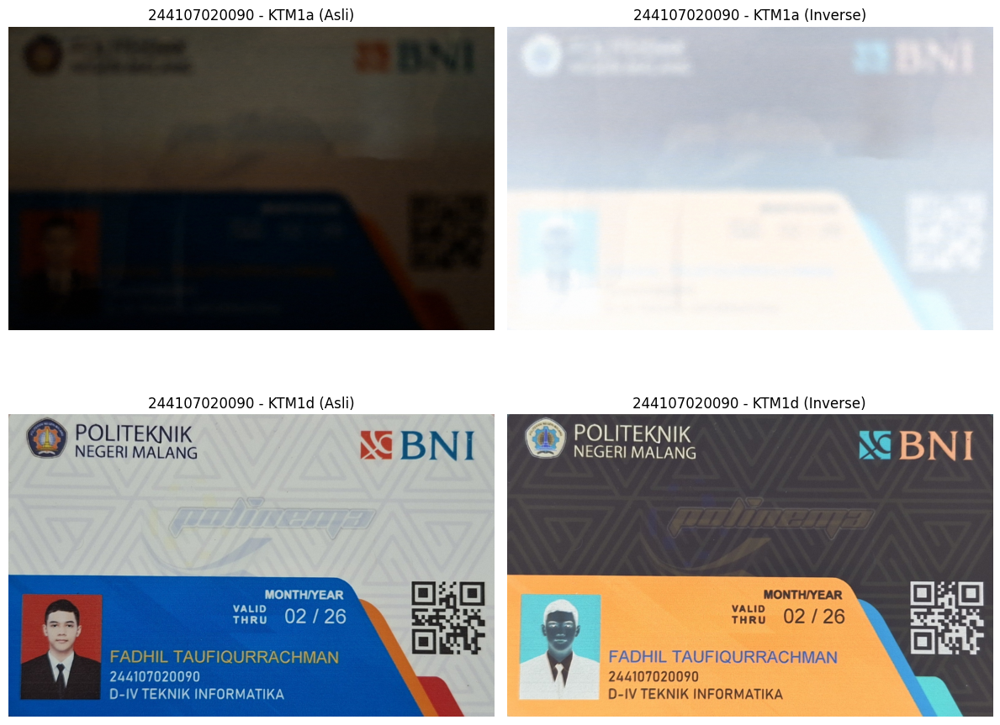

In [4]:
# Menggunakan rumus g(x) = 255 - f(x)

# 1. Membaca citra masukan
img_ktm1a = cv.imread(BASE_PATH + 'KTM1a.jpg') # Ruangan gelap
img_ktm1b = cv.imread(BASE_PATH + 'KTM1d.jpg') # Cahaya Matahari

if img_ktm1a is None or img_ktm1b is None:
    print("Error: Gambar tidak ditemukan. Cek kembali nama file di folder Drive Anda.")
else:
    # Mengubah format warna ke RGB untuk Matplotlib
    img_ktm1a_rgb = cv.cvtColor(img_ktm1a, cv.COLOR_BGR2RGB)
    img_ktm1b_rgb = cv.cvtColor(img_ktm1b, cv.COLOR_BGR2RGB)

    # 2. Implementasi Operasi Inverse Citra
    inv_ktm1a = 255 - img_ktm1a_rgb
    inv_ktm1b = 255 - img_ktm1b_rgb

    # 3. Menampilkan hasil berdampingan
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    # Baris 1: KTM1a (Ruangan Gelap)
    axes[0, 0].imshow(img_ktm1a_rgb)
    axes[0, 0].set_title(NIM + ' - KTM1a (Asli)')
    axes[0, 0].axis('off')

    axes[0, 1].imshow(inv_ktm1a)
    axes[0, 1].set_title(NIM + ' - KTM1a (Inverse)')
    axes[0, 1].axis('off')

    # Baris 2: KTM1b (Cahaya Matahari)
    axes[1, 0].imshow(img_ktm1b_rgb)
    axes[1, 0].set_title(NIM + ' - KTM1d (Asli)')
    axes[1, 0].axis('off')

    axes[1, 1].imshow(inv_ktm1b)
    axes[1, 1].set_title(NIM + ' - KTM1d (Inverse)')
    axes[1, 1].axis('off')

    plt.tight_layout()
    plt.show()


*   Mengapa KTM1a (Inverse) tampak pucat dan berkabut?
Citra asli KTM1a diambil di ruangan gelap, sehingga kebanyakan nilai intensitas pikselnya berada di angka yang sangat rendah (mendekati 0). Saat dioperasikan inverse dengan rumus g(x) = 255 - f(x), piksel yang bernilai sangat rendah tersebut dibalik menjadi bernilai sangat tinggi (mendekati 255 atau putih). Akibatnya, piksel pada gambar hasil inverse hanya menumpuk pada rentang nilai tinggi (warna terang) dan tidak memiliki piksel gelap (warna hitam). Ketiadaan warna hitam inilah yang membuat gambar kehilangan kedalaman (kontras rendah) sehingga terlihat pucat, rata, dan seolah tertutup kabut putih.  

*   Mengapa KTM1b (Inverse) tetap kontras?
Citra asli KTM1d diambil di luar ruangan dengan cahaya matahari. Citra ini memiliki kualitas pencahayaan yang baik dengan rentang histogram yang lebar. Terdapat piksel yang benar-benar gelap dan piksel yang benar-benar terang secara merata. Saat dibalik, warna hitam menjadi putih pekat dan warna putih menjadi hitam pekat. Karena sebaran intensitasnya dari awal sudah merata dan lebar, citra negatifnya tetap mempertahankan rentang nilai (kontras tinggi) yang merata tersebut, sehingga ketajaman objek tetap terjaga.



2. Transformasi Kontras

--- Mengubah kontras dan tingkat kecerahan citra ---
Nilai kecerahan (b) berdasarkan NIM : 49
Nilai kontras (a) berdasarkan dari NIM   : 1.0


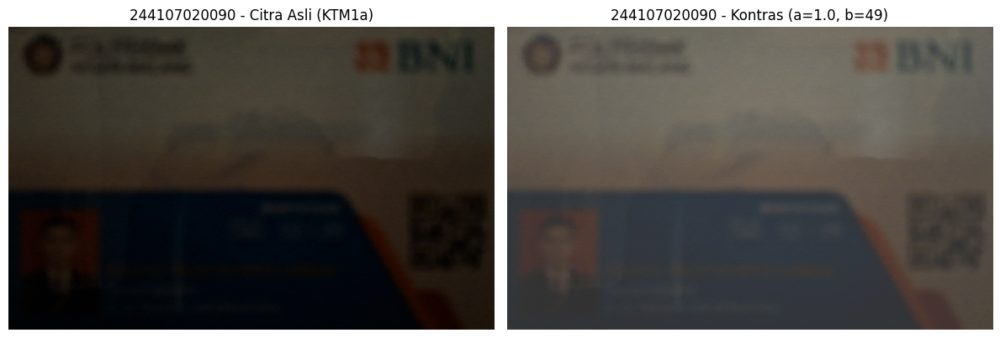

In [5]:
# Membaca citra KTM1a (Ruangan Gelap)
img_ktm1a = cv.imread(BASE_PATH + 'KTM1a.jpg')

if img_ktm1a is None:
    print("Error: Gambar KTM1a.jpg tidak ditemukan.")
else:
    # Konversi format warna BGR ke RGB
    img_ktm1a_rgb = cv.cvtColor(img_ktm1a, cv.COLOR_BGR2RGB)

    # Memanggil nilai parameter yang sudah dihitung di awal
    a = PARAM['a']
    b = PARAM['b']

    print("--- Mengubah kontras dan tingkat kecerahan citra ---")
    print(f"Nilai kecerahan (b) berdasarkan NIM : {b}")
    print(f"Nilai kontras (a) berdasarkan dari NIM   : {a}")

    # Implementasi Operasi Kontras
    # Mengubah tipe data ke float sementara agar hasil perkalian tidak error (wrap-around)
    # Kemudian di-clip ke rentang 0-255 dan dikembalikan ke uint8
    kontras_img = np.clip(a * img_ktm1a_rgb.astype(float) + b, 0, 255).astype(np.uint8)

    # Menampilkan hasil
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(img_ktm1a_rgb)
    axes[0].set_title(NIM + ' - Citra Asli (KTM1a)')
    axes[0].axis('off')

    axes[1].imshow(kontras_img)
    axes[1].set_title(NIM + f" - Kontras (a={a}, b={b})")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

Transformasi kontras menggunakan rumus g(x,y) = a * f(x,y) + b, di mana variabel a mengatur peregangan rentang warna dan b mengatur tingkat kecerahan. Perhitungan parameter menghasilkan nilai kontras a = 1.0 dan kecerahan b = 49. Secara perhitungan, mengalikan nilai piksel dengan angka 1.0 berarti lebar kurva histogram tidak berubah, sehingga tidak terjadi peningkatan ketajaman antar piksel sama sekali. Akibatnya, citra keluaran tampak lebih terang murni karena efek penambahan kecerahan dari parameter b, yang pemrosesannya tetap dibungkus dengan fungsi truncate (np.clip) untuk clipping, mencegah error nilai kembali ke 0 apabila akumulasi nilai piksel melebihi batas maksimal 255 atau sebaliknya.

3. Logarithmic Brightness Vs Linier Brightness

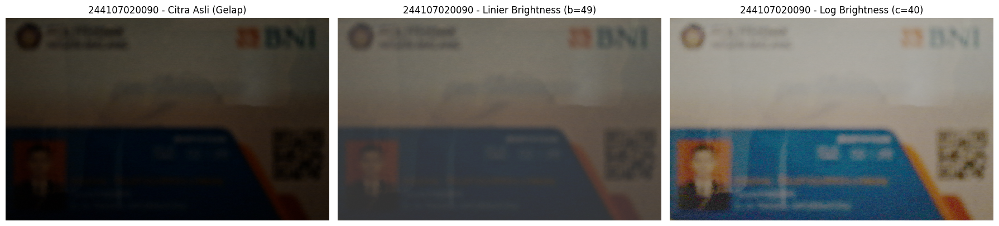

Jumlah piksel bernilai 255 di Logarithmic: 0
Jumlah piksel bernilai 255 di Linear: 0


In [6]:
img_ktm1a = cv.imread(BASE_PATH + 'KTM1a.jpg')

if img_ktm1a is None:
    print("Error: Gambar KTM1a.jpg tidak ditemukan.")
else:
    img_ktm1a_rgb = cv.cvtColor(img_ktm1a, cv.COLOR_BGR2RGB)

    b = PARAM['b'] # 49
    c = PARAM['c'] # 40

    # 1. Proses Linier Brightness (g(x,y) = f(x,y) + b)
    linier_img = np.clip(img_ktm1a_rgb.astype(float) + b, 0, 255).astype(np.uint8)

    # 2. Proses Logarithmic Brightness (s = c * log(1 + r))
    log_img = np.clip(c * np.log1p(img_ktm1a_rgb.astype(float)), 0, 255).astype(np.uint8)

    # Menampilkan hasil (3 kolom untuk perbandingan)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(img_ktm1a_rgb)
    axes[0].set_title(NIM + ' - Citra Asli (Gelap)')
    axes[0].axis('off')

    axes[1].imshow(linier_img)
    axes[1].set_title(NIM + f" - Linier Brightness (b={b})")
    axes[1].axis('off')

    axes[2].imshow(log_img)
    axes[2].set_title(NIM + f" - Log Brightness (c={c})")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    print('Jumlah piksel bernilai 255 di Logarithmic:', np.sum(log_img == 255))
    print('Jumlah piksel bernilai 255 di Linear:', np.sum(linier_img == 255))

Dari hasil perbandingan tersebut, terlihat bahwa dengan menggunakan logarithmic brightness, hasil citra lebih baik dibandingkan dengan linier. Logarithmic Brightness membuat visual lebih terlihat dibandingkan Linier Brightness karena kemampuannya meratakan rentang nilai piksel, yang gelap menjadi yang lebih terang sementara yang sudah terang akan ditekan kenaikannya. Linier brightness menggeser seluruh piksel ke atas secara seragam (sebesar 49 tingkat) sehingga kontras teks dan latar belakang tetap pudar. Terkait clipping atau pemotongan nilai piksel menjadi putih penuh, terbukti tidak ada nilai piksel 255. Hal ini dibuktikan secara matematis di mana nilai maksimum 255 yang dimasukkan ke rumus logaritma hanya menghasilkan keluaran maksimal sekitar 222, sehingga detail pada area terang tetap terjaga utuh meskipun titik putih paling cemerlangnya menjadi tampak sedikit keabu-abuan.

4. Grayscale (Averaging, Lightness, Luminance)

Metode Grayscale     | Rata-rata       | Simpangan Baku 
------------------------------------------------------------
Averaging            | 188.76          | 45.93          
Lightness            | 192.44          | 45.40          
Luminance            | 180.09          | 49.44          


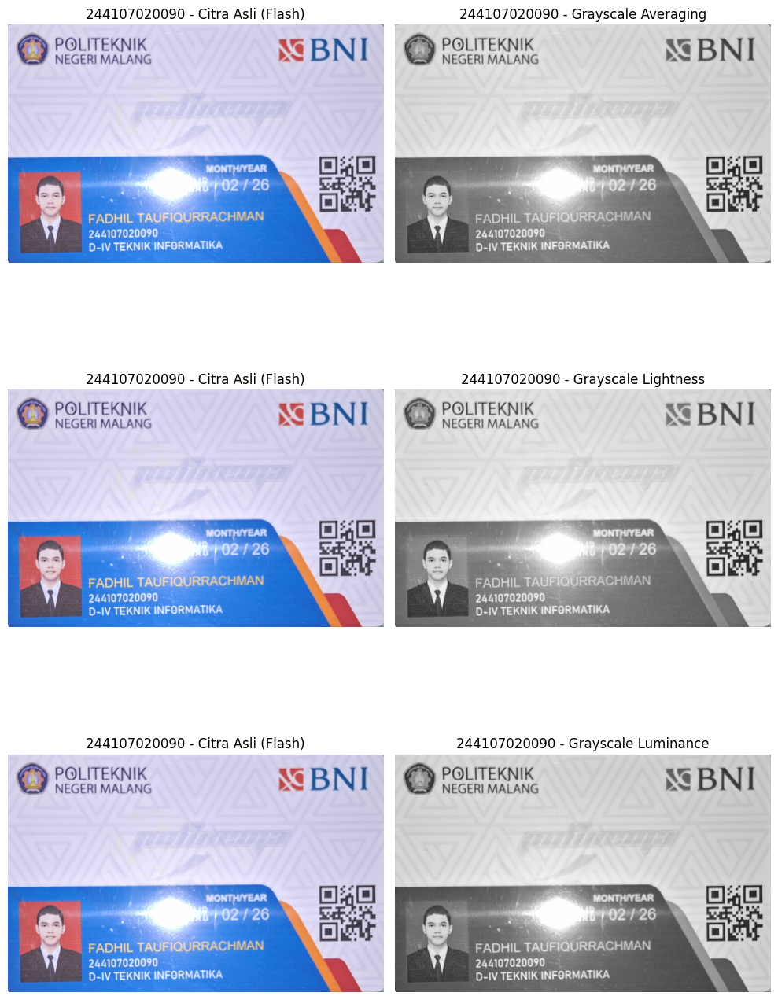

In [7]:
img_ktm1c = cv.imread(BASE_PATH + 'KTM1c.jpg')

if img_ktm1c is None:
    print("Error: Gambar KTM1c.jpg tidak ditemukan.")
else:
    # Konversi format warna BGR ke RGB
    img_ktm1c_rgb = cv.cvtColor(img_ktm1c, cv.COLOR_BGR2RGB)

    # Memisahkan channel warna dan mengonversi ke float untuk menghindari overflow matematis
    R = img_ktm1c_rgb[:, :, 0].astype(float)
    G = img_ktm1c_rgb[:, :, 1].astype(float)
    B = img_ktm1c_rgb[:, :, 2].astype(float)

    # 1. Metode Averaging: (R + G + B) / 3
    gray_avg = np.round((R + G + B) / 3).astype(np.uint8)

    # 2. Metode Lightness: (max(R,G,B) + min(R,G,B)) / 2
    RGB_float = img_ktm1c_rgb.astype(float)
    max_RGB = np.max(RGB_float, axis=2)
    min_RGB = np.min(RGB_float, axis=2)
    gray_light = np.round((max_RGB + min_RGB) / 2).astype(np.uint8)

    # 3. Metode Luminance: 0.299*R + 0.587*G + 0.114*B (Standar Rec. 601)
    gray_lum = np.round(0.299 * R + 0.587 * G + 0.114 * B).astype(np.uint8)

    # --- Perhitungan Statistik ---
    stats = {
        'Averaging': (np.mean(gray_avg), np.std(gray_avg)),
        'Lightness': (np.mean(gray_light), np.std(gray_light)),
        'Luminance': (np.mean(gray_lum), np.std(gray_lum))
    }

    # Mencetak Tabel Statistik
    print("=" * 60)
    print(f"{'Metode Grayscale':<20} | {'Rata-rata':<15} | {'Simpangan Baku':<15}")
    print("-" * 60)
    for method, (mean_val, std_val) in stats.items():
        print(f"{method:<20} | {mean_val:<15.2f} | {std_val:<15.2f}")
    print("=" * 60)

    # --- Visualisasi Hasil ---
    fig, axes = plt.subplots(3, 2, figsize=(10, 15))

    # a. Averaging
    axes[0, 0].imshow(img_ktm1c_rgb)
    axes[0, 0].set_title(NIM + ' - Citra Asli (Flash)')
    axes[0, 1].imshow(gray_avg, cmap='gray')
    axes[0, 1].set_title(NIM + ' - Grayscale Averaging')

    # b. Lightness
    axes[1, 0].imshow(img_ktm1c_rgb)
    axes[1, 0].set_title(NIM + ' - Citra Asli (Flash)')
    axes[1, 1].imshow(gray_light, cmap='gray')
    axes[1, 1].set_title(NIM + ' - Grayscale Lightness')

    # c. Luminance
    axes[2, 0].imshow(img_ktm1c_rgb)
    axes[2, 0].set_title(NIM + ' - Citra Asli (Flash)')
    axes[2, 1].imshow(gray_lum, cmap='gray')
    axes[2, 1].set_title(NIM + ' - Grayscale Luminance')

    # Hilangkan sumbu axis untuk kerapian
    for ax in axes.flat:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

Metode Luminance menghasilkan pemisahan paling jelas antara teks dan latar belakang kartu dibandingkan Averaging dan Lightness. Metode Luminance secara khusus memberikan bobot tertinggi pada channel hijau (0.587) yang paling sensitif bagi persepsi struktural mata manusia, dan memberikan bobot terendah pada channel biru (0.114) yang sering menjadi sumber silau dari kilat flash.

5. Image Masking Dengan Thresholding Warna (HSV)

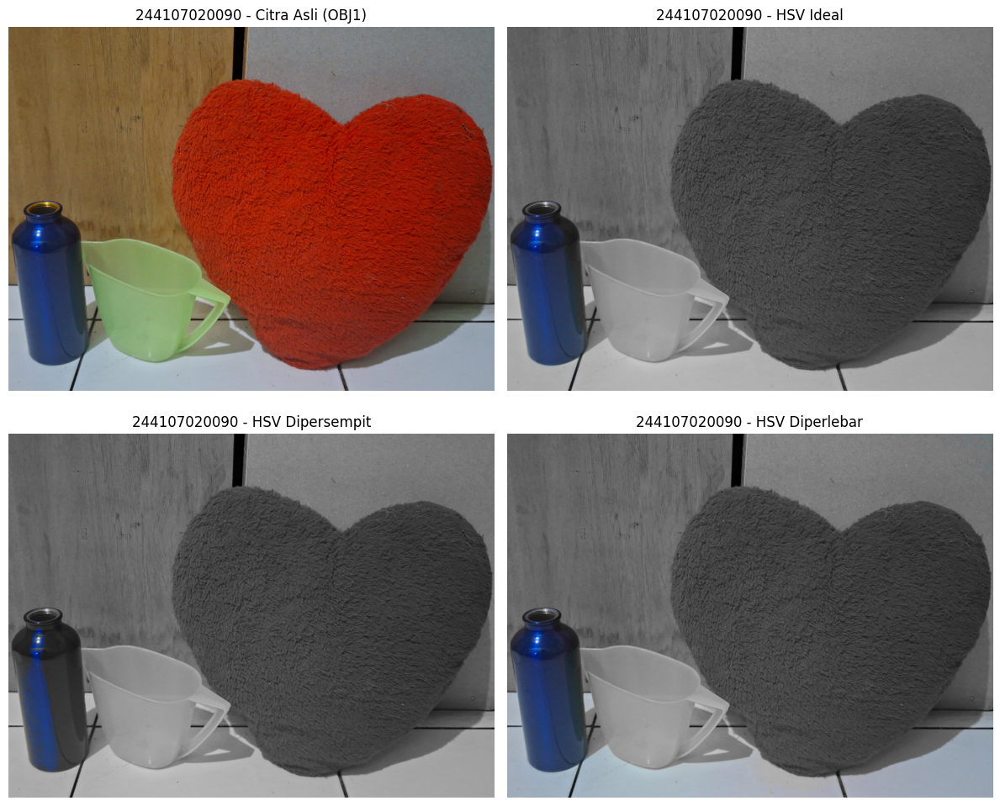

In [8]:
# Membaca citra objek pribadi (OBJ1.jpg)
img_obj1 = cv.imread(BASE_PATH + 'OBJ1.jpg')

if img_obj1 is None:
    print("Error: Gambar OBJ1.jpg tidak ditemukan. Pastikan file sudah ada di Drive.")
else:
    # 1. Konversi format warna
    img_obj1_rgb = cv.cvtColor(img_obj1, cv.COLOR_BGR2RGB)

    # Konversi ke HSV untuk kemudahan isolasi warna
    img_hsv = cv.cvtColor(img_obj1_rgb, cv.COLOR_RGB2HSV)

    # Buat versi grayscale dari citra asli, lalu ubah ke 3-channel
    img_gray = cv.cvtColor(img_obj1, cv.COLOR_BGR2GRAY)
    img_gray_3c = cv.cvtColor(img_gray, cv.COLOR_GRAY2RGB)

    # A. Rentang Ideal
    lower_ideal = np.array([100, 50, 50])
    upper_ideal = np.array([130, 255, 255])
    mask_ideal = cv.inRange(img_hsv, lower_ideal, upper_ideal)
    # Jika mask == 255 (putih/True), ambil piksel warna asli. Jika tidak, ambil abu-abu.
    res_ideal = np.where(mask_ideal[:, :, None] == 255, img_obj1_rgb, img_gray_3c)

    # B. Rentang Dipersempit (Hanya mengambil biru yang sangat pekat/terang)
    lower_narrow = np.array([110, 100, 100])
    upper_narrow = np.array([120, 255, 255])
    mask_narrow = cv.inRange(img_hsv, lower_narrow, upper_narrow)
    res_narrow = np.where(mask_narrow[:, :, None] == 255, img_obj1_rgb, img_gray_3c)

    # C. Rentang Diperlebar (Mengambil spektrum dari cyan hingga ungu gelap)
    lower_wide = np.array([85, 20, 20])
    upper_wide = np.array([145, 255, 255])
    mask_wide = cv.inRange(img_hsv, lower_wide, upper_wide)
    res_wide = np.where(mask_wide[:, :, None] == 255, img_obj1_rgb, img_gray_3c)

    # 2. Visualisasi Perbandingan
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    axes[0, 0].imshow(img_obj1_rgb)
    axes[0, 0].set_title(NIM + ' - Citra Asli (OBJ1)')

    axes[0, 1].imshow(res_ideal)
    axes[0, 1].set_title(NIM + ' - HSV Ideal')

    axes[1, 0].imshow(res_narrow)
    axes[1, 0].set_title(NIM + ' - HSV Dipersempit')

    axes[1, 1].imshow(res_wide)
    axes[1, 1].set_title(NIM + ' - HSV Diperlebar')

    for ax in axes.flat:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

Image masking ini memanfaatkan ruang warna HSV (Hue, Saturation, Value), memisahkan informasi warna murni (Hue) dari intensitas pencahayaan (Value), sehingga jauh lebih stabil dibandingkan memfilter warna langsung di ruang RGB.

6. Gamma Correction

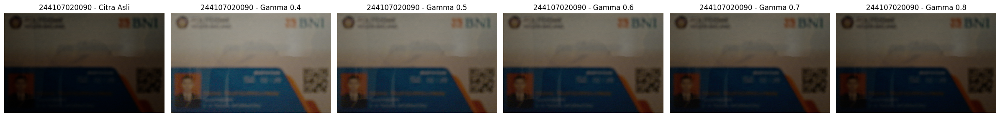

In [9]:
img_ktm1a = cv.imread(BASE_PATH + 'KTM1a.jpg')

if img_ktm1a is None:
    print("Error: Gambar KTM1a.jpg tidak ditemukan.")
else:
    img_ktm1a_rgb = cv.cvtColor(img_ktm1a, cv.COLOR_BGR2RGB)

    # Nilai gamma awal dari NIM (0.4)
    gamma_nim = PARAM['gamma']
    gamma_list = [0.4, 0.5, 0.6, 0.7, 0.8]

    def apply_gamma(image, gamma):
        table = np.array([((i / 255.0) ** gamma) * 255 for i in np.arange(0, 256)]).astype(np.uint8)
        return cv.LUT(image, table)

    # Visualisasi 6 kolom (1 asli + 5 variasi gamma)
    fig, axes = plt.subplots(1, 6, figsize=(24, 5))

    # Citra Asli
    axes[0].imshow(img_ktm1a_rgb)
    axes[0].set_title(NIM + ' - Citra Asli')
    axes[0].axis('off')

    # Iterasi penerapan gamma correction
    for i, g in enumerate(gamma_list):
        gamma_corrected = apply_gamma(img_ktm1a_rgb, g)
        axes[i+1].imshow(gamma_corrected)
        axes[i+1].set_title(NIM + f' - Gamma {g}')
        axes[i+1].axis('off')

    plt.tight_layout()
    plt.show()

Berdasarkan uji coba deret nilai gamma yang teratur (0.4 hingga 0.8), parameter gamma yang membuat detail teks dan NIM paling jelas terbaca adalah 0,4. Hal ini sesuai dengan prinsip transformasi pangkat; nilai gamma yang lebih kecil dari 1 akan memetakan rentang intensitas input yang gelap ke level output yang jauh lebih terang. Meskipun objek sama, nilai gamma terbaik pasti berbeda-beda. Hal ini disebabkan kondisi pencahayaan saat pengambilan gambar yang sangat bervariasi (bayangan ruangan, kualitas lensa smartphone, dll.), yang menghasilkan kurva intensitas piksel asli berbeda. Karena Gamma Correction beroperasi secara eksponensial berdasarkan intensitas asli setiap piksel, titik awal (kegelapan) yang berbeda menuntut nilai pangkat kompensasi yang berbeda pula untuk memunculkan detail yang hilang.

7. Simulasi Image Depth

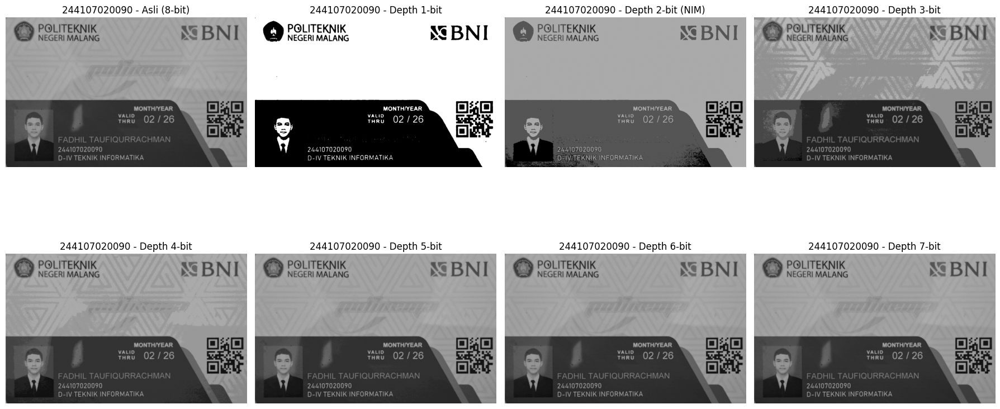

--- Kuantisasi Bit Depth ---
Nilai Bit Depth berdasarkan NIM: 2-bit
Kedalaman 1-bit -> Jumlah Warna: 2
Kedalaman 2-bit -> Jumlah Warna: 4
Kedalaman 3-bit -> Jumlah Warna: 8
Kedalaman 4-bit -> Jumlah Warna: 16
Kedalaman 5-bit -> Jumlah Warna: 32
Kedalaman 6-bit -> Jumlah Warna: 64
Kedalaman 7-bit -> Jumlah Warna: 128


In [14]:
# Baca KTM1b secara grayscale
original_gray = cv.imread(BASE_PATH + 'KTM1b.jpg', cv.IMREAD_GRAYSCALE)

if original_gray is None:
    print("Error: Gambar KTM1b.jpg tidak ditemukan.")
else:
    # 1. Parameter bit dari NIM
    bit_nim = PARAM['bit']

    # 2. Fungsi Simulasi Kuantisasi Bit Depth
    def kuantisasi_bit(img_gray, bit_depth):
        # Rumus jarak antar level: level = 255 / (2^bit - 1)
        level = 255 / (pow(2, bit_depth) - 1)
        # C' = round(C / level) * level
        depth_img = (np.round(img_gray / level)) * level
        return depth_img.astype(np.uint8)

    # 3. Visualisasi Hasil dari 1 hingga 7 bit
    fig, axes = plt.subplots(2, 4, figsize=(18, 10))
    axes = axes.flatten()

    # Tampilkan Citra Asli Grayscale 8-bit (posisi pertama)
    axes[0].imshow(original_gray, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title(NIM + ' - Asli (8-bit)')
    axes[0].axis('off')

    # Tampilkan simulasi 1-7 bit
    for bit in range(1, 8):
        img_quantized = kuantisasi_bit(original_gray, bit)
        title_suffix = " (NIM)" if bit == bit_nim else ""
        axes[bit].imshow(img_quantized, cmap='gray', vmin=0, vmax=255)
        axes[bit].set_title(NIM + f' - Depth {bit}-bit{title_suffix}')
        axes[bit].axis('off')

    plt.tight_layout()
    plt.show()

    # Cetak informasi tambahan untuk dianalisis
    print("--- Kuantisasi Bit Depth ---")
    print(f"Nilai Bit Depth berdasarkan NIM: {bit_nim}-bit")
    for i in range(1, 8):
        jml_warna = pow(2, i)
        print(f"Kedalaman {i}-bit -> Jumlah Warna: {jml_warna}")

Pada parameter bit hasil dari NIM saya (2-bit), jumlah warna yang tersedia hanya 4 variasi. Akibatnya, citra mengalami penurunan kualitas drastis karena detail bayangan yang halus diratakan secara paksa ke level warna terdekat.  Berdasarkan perbandingan keseluruhan dari kedalaman 1 hingga 7 bit, nama dan NIM pada kartu mahasiswa baru mulai dapat terbaca pada simulasi 3-bit. Pada kedalaman tersebut, jumlah level warna 8 sudah cukup untuk memisahkan batas gelap teks dari intensitas terang latar belakang kartu, meskipun belum sebagus seperti citra 8-bit asli (256 warna).

8. Average Denoising & Perhitungan PSNR

Berhasil membaca 100 citra bernoise.
| No  | Jml Citra  | Nilai PSNR (dB)      |
---------------------------------------------
| 1   | 10         | 19.7289              |
| 2   | 20         | 19.8373              |
| 3   | 40         | 19.8909              |
| 4   | 80         | 19.9162              |
| 5   | 100        | 19.9220              |


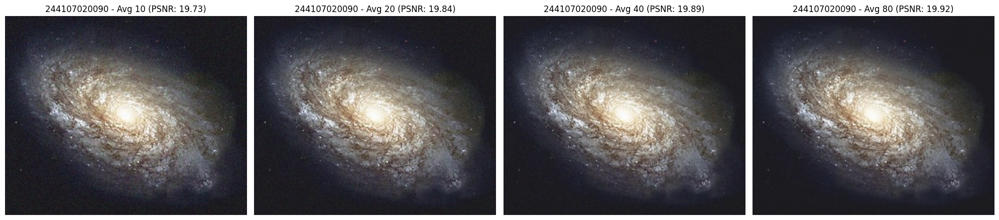

In [15]:
import glob
from math import log10, sqrt

# 1. Fungsi PSNR
def calculate_psnr(img1, img2):
    img1_float = img1.astype(np.float64)
    img2_float = img2.astype(np.float64)
    mse = np.mean((img1_float - img2_float) ** 2)
    if mse == 0:  # Jika MSE = 0, tidak ada selisih sama sekali
        return float('inf')
    max_pixel = 255.0
    psnr = 20 * log10(max_pixel / sqrt(mse))
    return psnr

# 2. Baca citra referensi (Ideal tanpa noise)
img_ideal = cv.imread(BASE_PATH + 'galaxy.jpg')

if img_ideal is None:
    print("Error: Citra galaxy.jpg tidak ditemukan. Cek folder Anda.")
else:
    # 3. Baca kumpulan 100 citra ber-noise menggunakan glob
    path_noises = BASE_PATH + 'noises/*.jpg'
    file_list = glob.glob(path_noises)

    cv_img = []
    for file in file_list:
        n = cv.imread(file)
        if n is not None:
            cv_img.append(n)

    print(f"Berhasil membaca {len(cv_img)} citra bernoise.")

    if len(cv_img) > 0:
        # Jumlah citra yang akan dirata-rata
        avg_steps = [10, 20, 40, 80, 100]
        results_psnr = []
        results_img = []

        # 4. Operasi Averaging Denoising
        for num in avg_steps:
            # Batasi array citra sebanyak 'num'
            num = min(num, len(cv_img))

            # Buat kanvas kosong bertipe float untuk akumulasi rata-rata
            # Float penting agar akumulasi ratusan piksel tidak overflow
            avg_canvas = np.zeros_like(img_ideal, dtype=np.float64)

            # Tambahkan nilai piksel dari setiap gambar
            for i in range(num):
                avg_canvas += cv_img[i].astype(np.float64)

            # Hitung rata-rata dan kembalikan ke tipe uint8
            avg_canvas /= num
            img_denoised = avg_canvas.astype(np.uint8)
            results_img.append(img_denoised)

            # Hitung PSNR dengan citra ideal
            psnr_val = calculate_psnr(img_ideal, img_denoised)
            results_psnr.append(psnr_val)

        # 5. Cetak Tabel Hasil
        print("=" * 45)
        print(f"| {'No':<3} | {'Jml Citra':<10} | {'Nilai PSNR (dB)':<20} |")
        print("-" * 45)
        for i, step in enumerate(avg_steps):
            psnr_str = f"{results_psnr[i]:.4f}" if i < len(results_psnr) else "N/A"
            print(f"| {i+1:<3} | {step:<10} | {psnr_str:<20} |")
        print("=" * 45)

        # 6. Visualisasi
        fig, axes = plt.subplots(1, 4, figsize=(20, 5))
        for i in range(min(4, len(results_img))):
            # Convert BGR to RGB for matplotlib display
            img_rgb = cv.cvtColor(results_img[i], cv.COLOR_BGR2RGB)
            axes[i].imshow(img_rgb)
            axes[i].set_title(NIM + f' - Avg {avg_steps[i]} (PSNR: {results_psnr[i]:.2f})')
            axes[i].axis('off')

        plt.tight_layout()
        plt.show()

*   Apakah peningkatan jumlah citra selalu memberikan peningkatan PSNR yang signifikan?
Tidak selalu. Berdasarkan hasil di atas, lompatan peningkatan paling terasa (sekitar +0.109 dB) hanya terjadi dari penggabungan 10 citra ke 20 citra. Setelah itu, peningkatan mulai melandai.

*   Pada jumlah citra berapa peningkatan mulai tidak terlalu signifikan?
Peningkatan mulai tidak signifikan sejak merata-ratakan 40 citra ke atas. Dapat dilihat dari hasil perbandingan, dari 40 citra (19.89 dB) ke 80 citra (19.91 dB), meskipun jumlah sampel ditambah 2 kali lipat, PSNR hanya naik tipis sebesar +0.02 dB. Hal serupa terjadi dari 80 citra ke 100 citra yang hanya bertambah 0.006 dB.

*   Apa kesimpulan yang Anda peroleh?
Metode Average Denoising sangat efektif mengurangi noise acak karena perataan nilai antar citra akan saling membatalkan noise tersebut. Terdapat titik diminishing returns (batas efektif penambahan), di mana memaksakan penambahan jumlah citra di atas 40 buah akan menghabiskan lebih banyak beban memori (RAM) dan waktu eksekusi CPU tanpa memberikan perbaikan visual yang signifikan.




9. Image Masking (Penyamaran Data Pribadi)

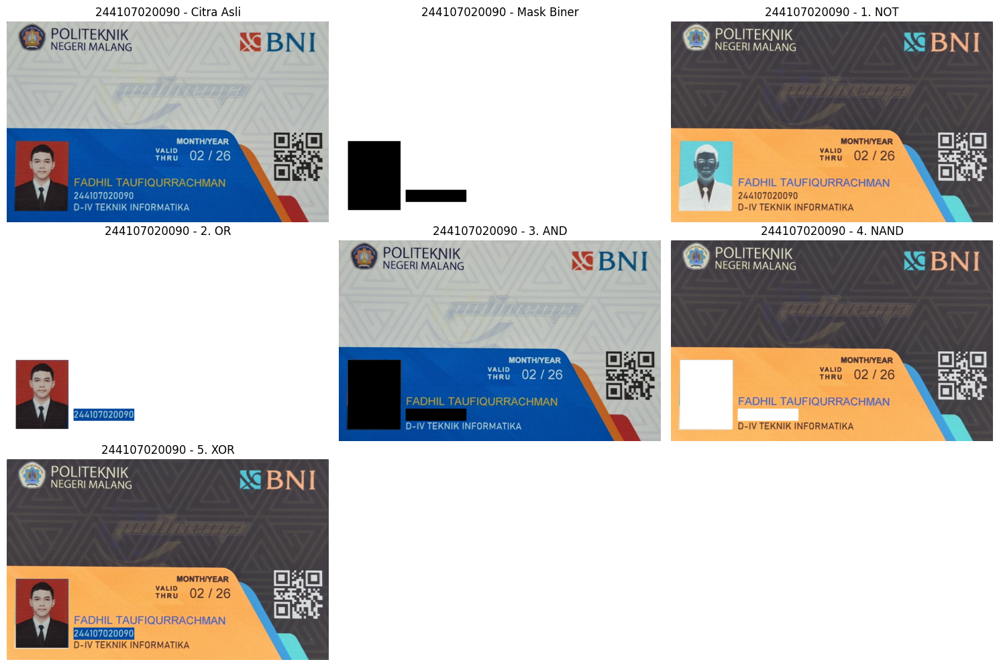

In [33]:
img_ktm1d = cv.imread(BASE_PATH + 'KTM1d.jpg')

if img_ktm1d is None:
    print("Error: Gambar KTM1d.jpg tidak ditemukan.")
else:
    img_ktm1d_rgb = cv.cvtColor(img_ktm1d, cv.COLOR_BGR2RGB)

    # Membuat Masking Biner
    mask = np.ones_like(img_ktm1d_rgb) * 255

    # Menghitamkan area Wajah
    mask[590:930, 45:305] = 0

    # Menghitamkan area NIM
    mask[830:890, 330:630] = 0

    # 1. NOT: Membalik semua nilai citra asli
    res_not = cv.bitwise_not(img_ktm1d_rgb)

    # 2. OR: Citra digabung Masking dengan logika ATAU
    res_or = cv.bitwise_or(img_ktm1d_rgb, mask)

    # 3. AND: Citra digabung Masking dengan logika DAN
    res_and = cv.bitwise_and(img_ktm1d_rgb, mask)

    # 4. NAND: NOT(AND), membalik hasil operasi AND
    res_nand = cv.bitwise_not(res_and)

    # 5. XOR: Citra digabung Masking dengan logika Exclusive OR
    res_xor = cv.bitwise_xor(img_ktm1d_rgb, mask)

    fig, axes = plt.subplots(3, 3, figsize=(15, 10))
    axes = axes.flatten()

    axes[0].imshow(img_ktm1d_rgb)
    axes[0].set_title(NIM + ' - Citra Asli')

    axes[1].imshow(mask)
    axes[1].set_title(NIM + ' - Mask Biner')

    axes[2].imshow(res_not)
    axes[2].set_title(NIM + ' - 1. NOT')

    axes[3].imshow(res_or)
    axes[3].set_title(NIM + ' - 2. OR')

    axes[4].imshow(res_and)
    axes[4].set_title(NIM + ' - 3. AND')

    axes[5].imshow(res_nand)
    axes[5].set_title(NIM + ' - 4. NAND')

    axes[6].imshow(res_xor)
    axes[6].set_title(NIM + ' - 5. XOR')

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

1. NOT (Komplemen): Hanya membalikkan seluruh nilai piksel, sehingga citra menjadi negatif.

2. OR: Mengembalikan nilai True (putih penuh) jika salah satu input bernilai True. Karena area luar mask putih, maka hasil luar mask akan hangus menjadi putih polos. Sebaliknya, area kotak wajah/NIM pada mask bernilai hitam. Artinya, wajah dan NIM justru menjadi satu-satunya yang terlihat, dikelilingi layar putih.

3. AND: Kebalikan dari OR. Mengalikan citra asli dengan nilai putih mempertahankan bagian luar citra agar tetap normal. Sementara area kotak wajah/NIM yang bernilai hitam mematikan piksel asli, sehingga wajah dan NIM berubah menjadi blok hitam solid. Ini adalah metode untuk menyensor data.

4.  NAND: Membalikkan hasil akhir dari logika AND. Area luar yang tadinya berwarna normal berubah menjadi negatif, dan area kotak sensor yang tadinya hitam menjadi blok putih menyala.

5. XOR (Exclusive-OR): Mengembalikan nilai True hanya jika inputnya berbeda, dan mengembalikan False jika inputnya sama persis. Berinteraksi dengan mask putih (255) akan menyebabkan warna citra asli menjadi kebalikannya (negatif), sedangkan berinteraksi dengan mask hitam tidak akan mengubah nilai asli citra. Hasilnya, area wajah dan NIM tampil dengan warna asli, sementara seluruh latar belakangnya menjadi warna klise negatif.

10. Enhancement Foto Malam Hari

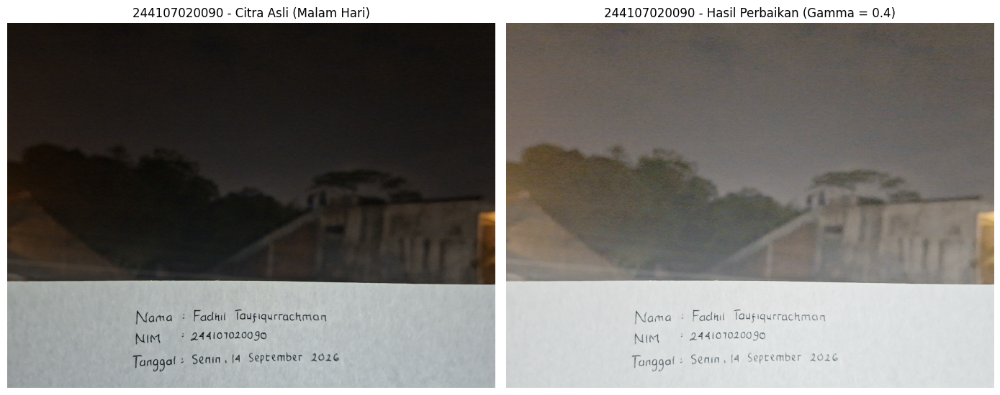

In [34]:
img_night = cv.imread(BASE_PATH + 'NIGHT1.jpg')

if img_night is None:
    print("Error: Gambar NIGHT1.jpg tidak ditemukan.")
else:
    img_night_rgb = cv.cvtColor(img_night, cv.COLOR_BGR2RGB)

    # Menentukan parameter terbaik
    best_gamma = 0.4

    # Proses Gamma Correction
    table = np.array([((i / 255.0) ** best_gamma) * 255 for i in np.arange(0, 256)]).astype(np.uint8)
    img_enhanced = cv.LUT(img_night_rgb, table)

    # Visualisasi Before-After
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(img_night_rgb)
    axes[0].set_title(NIM + ' - Citra Asli (Malam Hari)')
    axes[0].axis('off')

    axes[1].imshow(img_enhanced)
    axes[1].set_title(NIM + f' - Hasil Perbaikan (Gamma = {best_gamma})')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

**Metode yang dipilih:**
Gamma Correction.

**Alasan pemilihan:**
Foto malam hari memiliki distribusi histogram mayoritas piksel menumpuk di nilai intensitas gelap/mendekati nol. Jika menggunakan Linear Brightness, seluruh piksel akan digeser secara bersamaan, yang berisiko menyebabkan clipping (kehilangan detail menjadi putih polos) pada area yang sudah cukup terang. Sebaliknya, Gamma Correction beroperasi secara non-linier, yang secara signifikan mengangkat detail yang tersembunyi di area bayangan tanpa merusak piksel di area terang.

**Menentukan parameter terbaik:**
Berdasarkan eksperimen visual, nilai Gamma terbaik yang dipilih adalah 0.4. Nilai ini dipilih karena memberikan keseimbangan yang optimal, teks NIM dan tanggal pada kertas dapat terbaca dengan jelas, dan objek di latar belakang terlihat, namun efek samping berupa penguatan noise sensor kamera yang biasa terjadi di foto malam masih dalam batas toleransi dan belum merusak keseluruhan citra.

**Before-After:** Terlihat pada citra hasil perbaikan (kanan), latar belakang langit dan pepohonan yang sebelumnya hitam kelam menjadi terlihat, sementara tulisan identitas pada kertas putih di foreground tetap utuh dan jelas dibaca.